# DX603 — Homework 10: Monitoring and Improving Neural Networks

#### Due Date: Sunday, November 8th at 11:59pm (with 2 hour plus 1 minute grace period)

#### Total: 80 points

#### The late policy is described in the DX 603 Syllabus.

### Introduction

In Homework 09, you trained a neural network for **regression** and investigated mini-batch size and learning rate. In this homework, you will train a neural network for **binary classification** and investigate **learning curves, early stopping, model capacity, batch normalization, dropout, and L2 regularization**.

We return to the **UCI Spambase dataset** you used in **Homework 05 (logistic regression)**. The task is to classify emails as **0 = legitimate email (ham)** or **1 = spam**, using **57 numerical predictors** describing word frequencies, character frequencies, and capital-letter patterns. There are **4,601 observations**, roughly **39% spam**. We use the complete dataset with its original class distribution.

**Submission convention:** Write your code in the indicated cells, assign computed results to the `a...` answer variables, and run all protected **Graded Answer** cells. Use the fixed training/validation/test split. **Do not use the test set until Problem 5.**

**Primary model-selection metric:** Validation **ROC AUC** (higher is better), calculated from predicted probabilities. ROC AUC measures how well a model distinguishes spam from legitimate email across classification thresholds, whereas accuracy depends on a particular threshold and does not distinguish between types of classification errors.

We will also examine **binary cross-entropy** and learning curves, along with accuracy, precision, and recall at the **0.50 classification threshold**. Early stopping uses validation loss to determine when to stop training, while comparisons between model configurations use validation ROC AUC. You will not repeat the learning-rate or batch-size tuning from Homework 09.

In Problem 5, you will compare your final neural network with the logistic regression approach from Homework 05, using the **same held-out test observations**. Reflection 7.B asks you to interpret the relative strengths and limitations of the two approaches.

**Interpretation prompts:** Some problems include questions labeled **Consider (ungraded)**. These are intended to help you interpret your experimental results and prepare for the reflections in Problem 7. You do not need to submit written answers to these questions.

**Connection to the final project:** You are also working on your project milestone during this homework. Use these guided experiments to learn how to evaluate neural-network training and investigate possible improvements. For the milestone, a straightforward neural-network baseline is sufficient; you are **not required** to add dropout, batch normalization, or L2 regularization. More extensive model improvement belongs in the later final project submission.

In [3]:
# CPU compatibility and deterministic setup — run before any other TensorFlow imports
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["PYTHONHASHSEED"] = "42"
os.environ["TF_DETERMINISTIC_OPS"] = "1"

import tensorflow as tf
tf.config.set_visible_devices([], "GPU")
tf.keras.utils.set_random_seed(42)
print("TensorFlow:", tf.__version__)
print("Visible GPUs:", tf.config.get_visible_devices("GPU"))

I0000 00:00:1794181039.886756    2360 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794181073.624009    2360 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow: 2.22.0-rc0
Visible GPUs: []


E0000 00:00:1794181092.694170    2360 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



In [4]:
# Run once if ucimlrepo is not installed.
# Uncomment the next line if needed.

# %pip install ucimlrepo

In [5]:
# Imports and reproducibility
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, log_loss, confusion_matrix, ConfusionMatrixDisplay,
)
from tensorflow.keras import Sequential, regularizers
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization, Activation
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam

RANDOM_SEED = 42
BATCH_SIZE = 64
LEARNING_RATE = 0.001
MAX_EPOCHS = 120
PATIENCE = 8

tf.keras.utils.set_random_seed(RANDOM_SEED)


## Provided setup — binary spam classification

This is **the same UCI Spambase dataset (ID 94) and stratified 80/10/10 split with seed 42** used in Homework 05. We use all **4,601 emails and 57 numerical predictors**, without class sampling or rebalancing. Standardization is fitted **only on the training partition**, and the held-out test partition must remain unused until Problem 5.

The `ucimlrepo` package is required. If not installed, run `%pip install ucimlrepo` in a separate notebook cell, restart the kernel if needed, then run the notebook from the top. The first download requires internet access. You do not need to edit the data-loading cell.


In [6]:
# Load the UCI Spambase dataset from Homework 05 (ID 94).
# Use every observation; do not select classes or rebalance the dataset.
spam_data = fetch_ucirepo(id=94)
X = spam_data.data.features.copy()
y = spam_data.data.targets.squeeze().copy().astype(int).to_numpy(dtype=np.int32)
# Target: 0 = legitimate email (ham), 1 = spam.

# Exactly the Homework 05 split: stratified 80% training, 10% validation,
# and 10% held-out test, with seed 42 in both train_test_split calls.
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.10, stratify=y, random_state=RANDOM_SEED
)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=1/9, stratify=y_dev, random_state=RANDOM_SEED
)

# Fit the scaling step on training data ONLY, as in Homework 05.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train).astype("float32")
X_val_scaled = scaler.transform(X_val).astype("float32")
X_test_scaled = scaler.transform(X_test).astype("float32")

print("Training:", X_train_scaled.shape, np.bincount(y_train))
print("Validation:", X_val_scaled.shape, np.bincount(y_val))
print("Test:", X_test_scaled.shape, np.bincount(y_test))
print("Spam proportion:", f"{y.mean():.1%}")
print("Input features:", X_train_scaled.shape[1])
# IMPORTANT: Do not evaluate or inspect test results before Problem 5.


Training: (3680, 57) [2230 1450]
Validation: (460, 57) [279 181]
Test: (461, 57) [279 182]
Spam proportion: 39.4%
Input features: 57


In [7]:
# Provided utility: training and validation learning curves

def plot_history(history, title="Learning curves"):
    h = history.history
    epochs = np.arange(1, len(h["loss"]) + 1)
    best_epoch = int(np.argmin(h["val_loss"])) + 1
    fig, axes = plt.subplots(2, 1, figsize=(8, 7), sharex=True)
    axes[0].plot(epochs, h["loss"], label="Training loss")
    axes[0].plot(epochs, h["val_loss"], label="Validation loss")
    axes[0].axvline(best_epoch, linestyle=":", color="gray",
                    label=f"Min val loss: {best_epoch}")
    axes[0].set_ylabel("BCE + any L2 penalty")
    axes[0].legend()
    axes[0].grid(True)
    axes[1].plot(epochs, h["auc"], label="Training ROC AUC")
    axes[1].plot(epochs, h["val_auc"], label="Validation ROC AUC")
    axes[1].axvline(best_epoch, linestyle=":", color="gray")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("ROC AUC")
    axes[1].legend()
    axes[1].grid(True)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

# Keras's reported loss includes any L2 regularization penalty.
# Do not rank models with different L2 strengths using val_loss.
# Model selection uses validation ROC AUC computed from predicted probabilities.
# Early stopping monitors val_loss separately *within* each training run.


## Problem 1 — Build and Evaluate a Binary-Classification Network [10 points]

In this problem, you will establish a baseline neural network for predicting whether an email is spam. You will train the network without early stopping so that you can examine its learning curves and compare its performance with the early-stopping model in Problem 2.

Use the same hidden-layer architecture as Homework 09:

- **Input:** 57 numerical predictors.
- **First hidden layer:** 64 ReLU neurons.
- **Second hidden layer:** 32 ReLU neurons.
- **Output layer:** One sigmoid neuron, producing the predicted probability of spam.

Use **He initialization** (`kernel_initializer="he_normal"`) for both hidden layers, **binary cross-entropy** loss, and the Adam optimizer with `learning_rate=0.001`. Track accuracy and ROC AUC using:

```python
metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
```

### Instructions

1. Reset the random seed to `42`, then build and compile a **new neural network** with the architecture and settings specified above.
2. Train for **80 epochs**, using **batch size 64**, the fixed validation set, and `verbose=0`. Do **not** use early stopping in this problem.
3. Plot the training and validation **loss and ROC AUC learning curves** using the provided `plot_history()` function.
4. Generate predicted probabilities for the training and validation sets. Calculate **training and validation ROC AUC** using `roc_auc_score()`. Also compute classification accuracy at the **0.50 threshold**.
5. Use the trained model to determine the number of **trainable parameters in the final output Dense layer**, including its bias.

**Consider (ungraded):** Compare the training and validation ROC AUC values and examine the learning curves. Is there evidence that the model is overfitting? What happens to validation loss as training continues?

### Graded Answers

- `a1a`: Training ROC AUC at the end of training.
- `a1b`: Validation ROC AUC at the end of training.
- `a1c`: Number of trainable parameters in the final output Dense layer.

Use **computed expressions**, not manually entered numerical results. Remember that **ROC AUC must be calculated from predicted probabilities, not 0/1 class predictions**.

E0000 00:00:1794181096.651995    2360 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


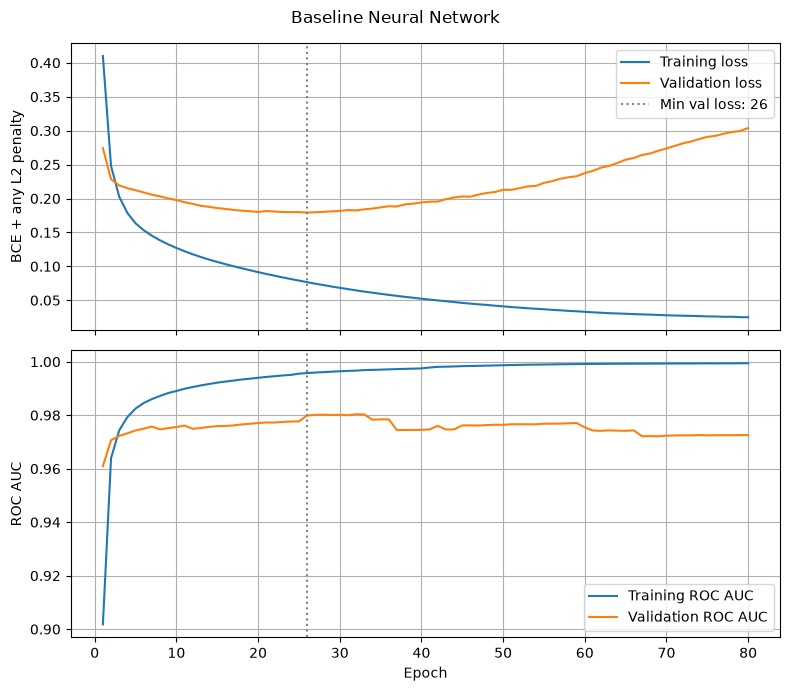

Training ROC AUC: 0.9997126952218957
Validation ROC AUC: 0.9804748608883344
Training accuracy: 0.9918478260869565
Validation accuracy: 0.9347826086956522


E0000 00:00:1794181113.178528    2360 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


In [8]:
# Your code here; add cells as needed

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(RANDOM_SEED)

baseline_model = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),
    Dense(64, activation="relu", kernel_initializer="he_normal"),
    Dense(32, activation="relu", kernel_initializer="he_normal"),
    Dense(1, activation="sigmoid")
])

baseline_model.compile(
    optimizer=Adam(learning_rate=LEARNING_RATE),
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
)

baseline_history = baseline_model.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=80,
    batch_size=BATCH_SIZE,
    verbose=0
)

plot_history(baseline_history, "Baseline Neural Network")

train_prob = baseline_model.predict(
    X_train_scaled,
    verbose=0
).ravel()

val_prob = baseline_model.predict(
    X_val_scaled,
    verbose=0
).ravel()

train_auc = roc_auc_score(y_train, train_prob)
val_auc = roc_auc_score(y_val, val_prob)

train_accuracy = accuracy_score(y_train, train_prob >= 0.50)
val_accuracy = accuracy_score(y_val, val_prob >= 0.50)

print("Training ROC AUC:", train_auc)
print("Validation ROC AUC:", val_auc)
print("Training accuracy:", train_accuracy)
print("Validation accuracy:", val_accuracy)

#### Problem 1 Graded Answers

In [9]:
# Your answer here — use a computed expression or variable
a1a = train_auc

In [10]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting
print(f"a1a = {a1a:.4f}")

a1a = 0.9997


In [11]:
# Your answer here — use a computed expression or variable
a1b = val_auc

In [12]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting
print(f"a1b = {a1b:.4f}")

a1b = 0.9805


In [13]:
# Your answer here — use a computed expression or variable
a1c = baseline_model.layers[-1].count_params()

In [14]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting
print(f"a1c = {a1c}")

a1c = 33


## Problem 2 — Learning Curves and Early Stopping [10 points]

In Problem 1, you trained the baseline network for a fixed 80 epochs. In this problem, you will investigate whether **early stopping** can reduce unnecessary training and improve generalization.

Build a **fresh copy of the same baseline network**, keeping the training and validation sets, architecture, initialization, optimizer, learning rate, and batch size unchanged.

### Instructions

1. Reset the random seed to `42`, then build and compile a **new model**, using the same settings as Problem 1.

2. Configure early stopping using:

   ```python
   EarlyStopping(
       monitor="val_loss",
       patience=8,
       min_delta=0.0,
       restore_best_weights=True
   )
   ```

   The callback monitors validation loss and restores the model weights from the epoch with the lowest observed validation loss.

3. Train for at most **120 epochs**, using **batch size 64**, the fixed validation set, and `verbose=0`. Track accuracy and ROC AUC as in Problem 1.

4. Plot the training and validation learning curves using `plot_history()`. From the recorded training history, determine:
   - The epoch with the **lowest validation loss** (numbering epochs starting at 1).
   - The **number of epochs actually trained**.

5. Generate predicted probabilities from the **restored model** on the validation set and calculate its **validation ROC AUC** using `roc_auc_score()`. Do **not** evaluate on the test set.

**Consider (ungraded):** Why might the epoch with the minimum validation loss differ from the epoch when training stopped? How does early stopping affect training duration and validation performance compared with Problem 1? Does early stopping necessarily improve ROC AUC?

### Graded Answers

- `a2a`: Epoch number with the minimum validation loss (starting at 1).
- `a2b`: Number of epochs actually trained.
- `a2c`: Validation ROC AUC of the **restored model**, calculated from predicted probabilities.

Keep your trained model in `es_model` and its history in `es_history` for later comparisons.

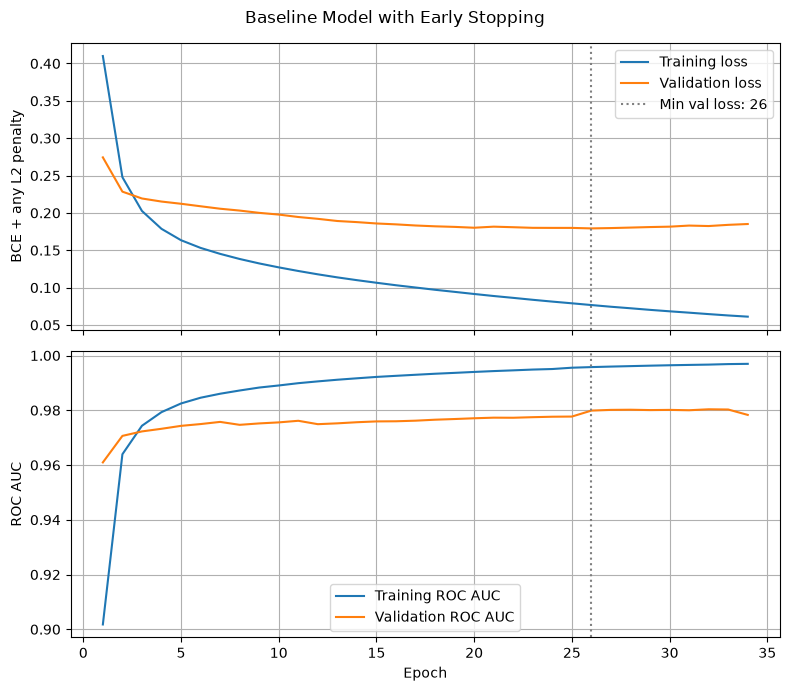

Best epoch: 26
Epochs trained: 34
Validation ROC AUC: 0.9813263628982751


E0000 00:00:1794181121.742546    2360 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


In [15]:
# Your code here; add cells as needed

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(RANDOM_SEED)

es_model = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),
    Dense(64, activation="relu", kernel_initializer="he_normal"),
    Dense(32, activation="relu", kernel_initializer="he_normal"),
    Dense(1, activation="sigmoid")
])

es_model.compile(
    optimizer=Adam(learning_rate=LEARNING_RATE),
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=8,
    min_delta=0.0,
    restore_best_weights=True
)

es_history = es_model.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=MAX_EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stopping],
    verbose=0
)

plot_history(es_history, "Baseline Model with Early Stopping")

best_epoch = int(np.argmin(es_history.history["val_loss"])) + 1
epochs_trained = len(es_history.history["loss"])

es_val_prob = es_model.predict(
    X_val_scaled,
    verbose=0
).ravel()

es_val_auc = roc_auc_score(y_val, es_val_prob)

print("Best epoch:", best_epoch)
print("Epochs trained:", epochs_trained)
print("Validation ROC AUC:", es_val_auc)

#### Problem 2 Graded Answers

In [16]:
# Your answer here — use a computed expression or variable
a2a = best_epoch

In [17]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting
print(f"a2a = {a2a}")

a2a = 26


In [18]:
# Your answer here — use a computed expression or variable
a2b = epochs_trained

In [19]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting
print(f"a2b = {a2b}")

a2b = 34


In [20]:
# Your answer here — use a computed expression or variable
a2c = es_val_auc

In [21]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting
print(f"a2c = {a2c:.4f}")

a2c = 0.9813


## Provided Helpers for Problems 3–5

The following helper functions allow you to compare neural-network configurations without repeatedly writing the same Keras code. Each experiment starts with a **new network**, resets the random seed for reproducibility, and uses the same training procedure. **The test set is not used during these experiments.**

The helpers use **He initialization** for hidden Dense layers with ReLU activations. When batch normalization is enabled, each hidden layer follows the sequence `Dense` (without activation) → `BatchNormalization` → `ReLU`. Dropout, when enabled, follows each hidden layer, and L2 regularization is applied to the hidden Dense-layer weights.

**Two evaluation metrics serve different purposes:**

- **Validation loss (`val_loss`)** determines when to stop training and which weights to restore within each experiment.
- **Validation ROC AUC**, calculated from predicted probabilities, is the primary metric for comparing different configurations and selecting the final model.

The helpers also calculate **prediction-only validation binary cross-entropy (`val_bce`)**. Unlike Keras's `val_loss`, this excludes regularization penalties, allowing direct comparison of predictive loss across configurations with different L2 strengths.

Use **validation ROC AUC** for model selection, not Keras's penalized validation loss.

In [22]:
# Provided functions; no edits are required

def build_classifier(hidden_units=(64, 32), batch_norm=False,
                     dropout_rate=0.0, l2_strength=0.0):
    model_layers = [Input(shape=(X_train_scaled.shape[1],))]
    for width in hidden_units:
        model_layers.append(Dense(
            width,
            activation=None if batch_norm else "relu",
            kernel_initializer="he_normal",
            kernel_regularizer=(regularizers.l2(l2_strength)
                                if l2_strength > 0 else None),
            use_bias=not batch_norm,
        ))
        if batch_norm:
            model_layers.append(BatchNormalization())
            model_layers.append(Activation("relu"))
        if dropout_rate > 0:
            model_layers.append(Dropout(dropout_rate))
    model_layers.append(Dense(1, activation="sigmoid"))
    return Sequential(model_layers)

# Records available for selection in Problem 5.
experiment_results = {}

def run_experiment(name, hidden_units=(64, 32), batch_norm=False,
                   dropout_rate=0.0, l2_strength=0.0):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(RANDOM_SEED)
    config = dict(hidden_units=tuple(hidden_units), batch_norm=batch_norm,
                  dropout_rate=dropout_rate, l2_strength=l2_strength)
    model = build_classifier(**config)
    model.compile(optimizer=Adam(learning_rate=LEARNING_RATE),
                  loss="binary_crossentropy",
                  metrics=["accuracy", tf.keras.metrics.AUC(name="auc")])
    callback = EarlyStopping(monitor="val_loss", patience=PATIENCE,
                             min_delta=0.0, restore_best_weights=True)
    history = model.fit(
        X_train_scaled, y_train,
        validation_data=(X_val_scaled, y_val),
        epochs=MAX_EPOCHS, batch_size=BATCH_SIZE,
        callbacks=[callback], verbose=0,
    )
    train_prob = model.predict(X_train_scaled, verbose=0).ravel()
    val_prob = model.predict(X_val_scaled, verbose=0).ravel()
    train_accuracy = accuracy_score(y_train, train_prob >= 0.5)
    val_accuracy = accuracy_score(y_val, val_prob >= 0.5)
    train_auc = roc_auc_score(y_train, train_prob)
    val_auc = roc_auc_score(y_val, val_prob)
    prediction_only_bce = log_loss(y_val, val_prob, labels=[0, 1])
    record = dict(
        name=name, config=config, model=model, history=history,
        train_accuracy=float(train_accuracy), val_accuracy=float(val_accuracy),
        train_auc=float(train_auc), val_auc=float(val_auc),
        val_bce=float(prediction_only_bce),
        best_epoch=int(np.argmin(history.history["val_loss"])) + 1,
        epochs_ran=len(history.history["loss"]),
        parameters=int(model.count_params()),
    )
    experiment_results[name] = record
    print(f"{name:19} val ROC AUC={val_auc:.4f}, "
          f"val accuracy={val_accuracy:.4f}, "
          f"val BCE={prediction_only_bce:.4f}, "
          f"best epoch={record['best_epoch']}, epochs={record['epochs_ran']}")
    return record

def comparison_table(names):
    fields = ("name", "parameters", "train_auc", "val_auc",
              "train_accuracy", "val_accuracy", "val_bce",
              "best_epoch", "epochs_ran")
    return pd.DataFrame([{
        f: experiment_results[name][f] for f in fields
    } for name in names]).sort_values(
        ["val_auc", "name"], ascending=[False, True]
    ).reset_index(drop=True)


## Problem 3 — Model Capacity and Batch Normalization [15 points]

In this problem, you will investigate how **model capacity** and **batch normalization** affect neural-network training and generalization.

Model capacity refers to a network's ability to represent complex relationships. One way to change capacity is to vary the number and size of hidden layers.

Use the provided `run_experiment()` helper for all four experiments. Keep the **random seed, learning rate, batch size, validation set, early-stopping settings, and maximum number of epochs** unchanged. All models use ReLU activations and He initialization.

### Instructions

1. Train three networks with different capacities, without batch normalization, dropout, or L2 regularization:
   - **Small:** One hidden layer with 16 neurons, `hidden_units=(16,)`.
   - **Baseline:** Two hidden layers with 64 and 32 neurons, `hidden_units=(64, 32)`.
   - **Large:** Three hidden layers with 128, 64, and 32 neurons, `hidden_units=(128, 64, 32)`.

2. Train a fourth network using the **baseline architecture** `(64, 32)`, but with `batch_norm=True`. Leave dropout and L2 regularization disabled.

3. Use `comparison_table()` to compare all four configurations, including training and validation ROC AUC, parameter counts, and training duration. Plot the learning curves for at least the **small**, **large**, and **batch-normalized** networks using `plot_history()`.

4. Use the following experiment names exactly:

   `small`, `baseline`, `large`, `batch_norm`

**Consider (ungraded):** Compare the training and validation ROC AUC values across the four models. Does the small network show evidence of underfitting, such as relatively low performance on both sets? Does the large network show evidence of overfitting, such as high training ROC AUC but noticeably lower validation ROC AUC? Does increasing capacity improve validation performance? What effect does batch normalization have?

Remember that **increasing model capacity or adding batch normalization does not necessarily improve generalization**.

### Graded Answers

- `a3a`: Name (string) of the configuration with the highest validation ROC AUC among the four runs, breaking exact ties alphabetically.
- `a3b`: Validation ROC AUC of the batch-normalized model.
- `a3c`: Total number of parameters in the **large network**, including weights and biases.
- `a3d`: Training ROC AUC minus validation ROC AUC for the large network.

In [23]:
# Your code here; add cells as needed

small = run_experiment(
    "small",
    hidden_units=(16,)
)

baseline = run_experiment(
    "baseline",
    hidden_units=(64, 32)
)

large = run_experiment(
    "large",
    hidden_units=(128, 64, 32)
)

batch_norm = run_experiment(
    "batch_norm",
    hidden_units=(64, 32),
    batch_norm=True
)

E0000 00:00:1794181139.789217    2360 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


small               val ROC AUC=0.9843, val accuracy=0.9478, val BCE=0.1598, best epoch=97, epochs=105


E0000 00:00:1794181148.142129    2360 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


baseline            val ROC AUC=0.9813, val accuracy=0.9500, val BCE=0.1793, best epoch=26, epochs=34


E0000 00:00:1794181153.671880    2360 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


large               val ROC AUC=0.9793, val accuracy=0.9435, val BCE=0.1780, best epoch=10, epochs=18
batch_norm          val ROC AUC=0.9736, val accuracy=0.9522, val BCE=0.1841, best epoch=14, epochs=22


E0000 00:00:1794181161.638731    2360 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


In [24]:
capacity_names = [
    "small",
    "baseline",
    "large",
    "batch_norm"
]

capacity_table = comparison_table(capacity_names)

display(capacity_table)

,name,parameters,train_auc,val_auc,train_accuracy,val_accuracy,val_bce,best_epoch,epochs_ran
0,small,945,0.994595,0.984297,0.966576,0.947826,0.159773,97,105
1,baseline,5825,0.996683,0.981326,0.977174,0.950000,0.179276,26,34
2,large,17793,0.996015,0.979326,0.977717,0.943478,0.177964,10,18
3,batch_norm,6113,0.991584,0.973643,0.959239,0.952174,0.184100,14,22


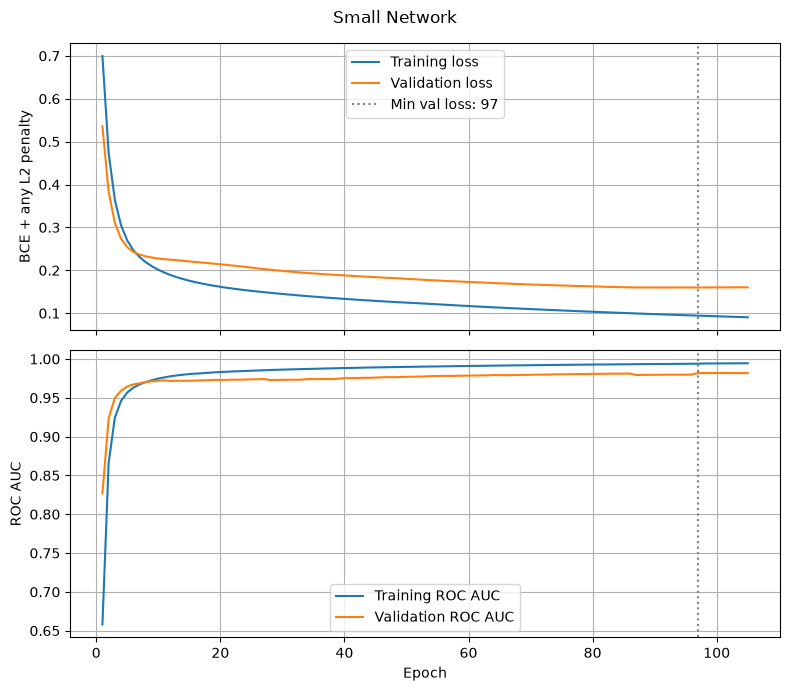

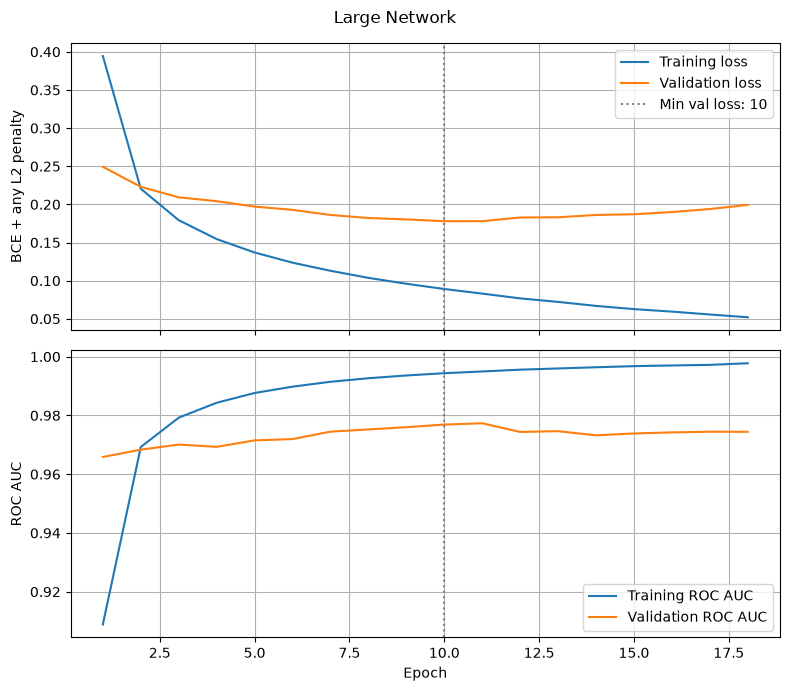

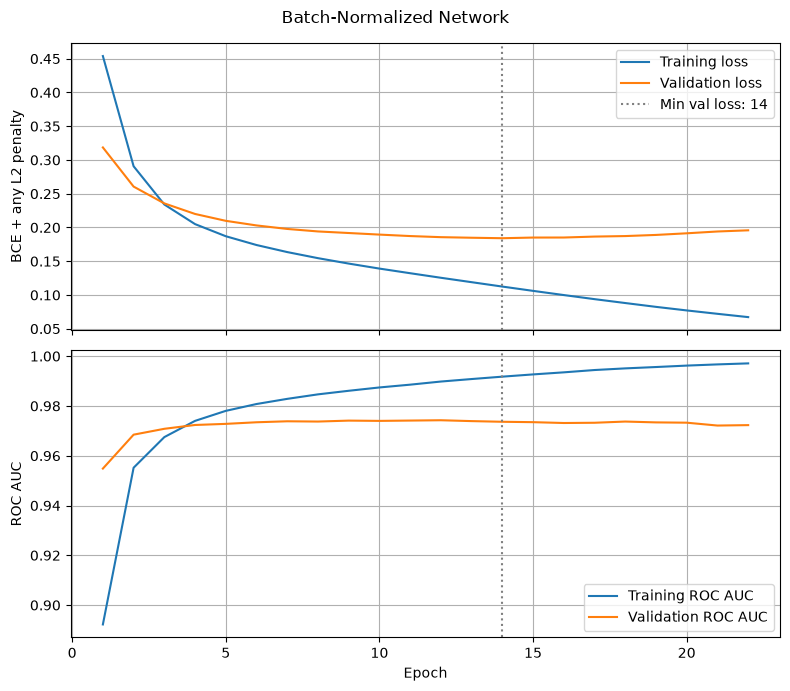

In [25]:
plot_history(
    experiment_results["small"]["history"],
    "Small Network"
)

plot_history(
    experiment_results["large"]["history"],
    "Large Network"
)

plot_history(
    experiment_results["batch_norm"]["history"],
    "Batch-Normalized Network"
)

#### Problem 3 Graded Answers

In [26]:
# Your answer here — use a computed expression or variable
a3a = capacity_table.loc[0, "name"]

In [27]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting
print(f"a3a = {a3a}")

a3a = small


In [28]:
# Your answer here — use a computed expression or variable
a3b = experiment_results["batch_norm"]["val_auc"]

In [29]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting
print(f"a3b = {a3b:.4f}")

a3b = 0.9736


In [30]:
# Your answer here — use a computed expression or variable
a3c = experiment_results["large"]["parameters"]

In [31]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting
print(f"a3c = {a3c}")

a3c = 17793


In [32]:
# Your answer here — use a computed expression or variable
a3d = (
    experiment_results["large"]["train_auc"]
    - experiment_results["large"]["val_auc"]
)

In [33]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting
print(f"a3d = {a3d:.4f}")

a3d = 0.0167


## Problem 4 — Dropout and L2 Regularization [15 points]

In this problem, you will investigate two techniques for controlling overfitting: **dropout** and **L2 regularization**.

Both techniques discourage a neural network from fitting the training data too closely, but they operate differently. Dropout randomly disables some hidden-layer activations during training, while L2 regularization penalizes large weights. Neither technique guarantees improved validation performance.

Use the **baseline architecture `(64, 32)` without batch normalization**. Train four new networks using `run_experiment()`, changing only the regularization settings shown below. Keep all other training settings unchanged.

| Experiment name | Dropout after each hidden layer | L2 strength for each hidden Dense layer |
|---|---:|---:|
| `dropout_025` | 0.25 | 0 |
| `dropout_050` | 0.50 | 0 |
| `l2_1e4` | 0 | 0.0001 |
| `dropout_l2` | 0.25 | 0.0001 |

### Instructions

1. Train the four configurations using `run_experiment()` and the exact experiment names shown above.

2. Include the **unregularized baseline** from Problem 3 in your comparisons. You do not need to retrain it.

3. Use `comparison_table()` to display a table comparing all five configurations. Include:
   - Training and validation ROC AUC.
   - Training and validation accuracy.
   - Prediction-only validation binary cross-entropy (`val_bce`).
   - Number of epochs actually trained.

4. Use `plot_history()` to compare the learning curves for the **baseline and two contrasting regularized configurations**. For example, compare the baseline, dropout 0.50, and L2-only models. You do not need to plot every configuration.

**Consider (ungraded):** Does dropout 0.50 appear to cause underfitting, as indicated by reduced training and validation performance? Does L2 reduce the gap between training and validation ROC AUC? Does combining dropout and L2 improve validation performance compared with either technique alone?

Remember that **stronger regularization does not necessarily produce a better model**.

### Important: Comparing Regularized Models

Keras includes L2 penalties in its reported training and validation losses. Consequently, these losses are not directly comparable with those from models without L2.

The helper separately calculates **prediction-only validation BCE (`val_bce`)**, which excludes the L2 penalty.

Because dropout is active during training but disabled during inference, use the **training and validation ROC AUC values calculated by the helper in inference mode** when examining generalization gaps.

Use **validation ROC AUC** as the primary metric for comparing configurations.

### Graded Answers

- `a4a`: Name (string) of the configuration with the highest validation ROC AUC among `baseline` and the four regularization experiments, breaking exact ties alphabetically.
- `a4b`: Validation ROC AUC of the selected configuration.
- `a4c`: Validation ROC AUC of the `dropout_050` model.
- `a4d`: Prediction-only validation BCE (`val_bce`) of the `l2_1e4` model.

In [34]:
# Your code here; add cells as needed
dropout_025 = run_experiment(
    "dropout_025",
    hidden_units=(64, 32),
    dropout_rate=0.25
)

dropout_050 = run_experiment(
    "dropout_050",
    hidden_units=(64, 32),
    dropout_rate=0.50
)

l2_1e4 = run_experiment(
    "l2_1e4",
    hidden_units=(64, 32),
    l2_strength=0.0001
)

dropout_l2 = run_experiment(
    "dropout_l2",
    hidden_units=(64, 32),
    dropout_rate=0.25,
    l2_strength=0.0001
)


E0000 00:00:1794181168.379404    2360 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


dropout_025         val ROC AUC=0.9759, val accuracy=0.9522, val BCE=0.1960, best epoch=11, epochs=19


E0000 00:00:1794181174.644870    2360 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


dropout_050         val ROC AUC=0.9747, val accuracy=0.9435, val BCE=0.1949, best epoch=10, epochs=18


E0000 00:00:1794181185.431659    2360 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


l2_1e4              val ROC AUC=0.9817, val accuracy=0.9478, val BCE=0.1783, best epoch=28, epochs=36
dropout_l2          val ROC AUC=0.9758, val accuracy=0.9478, val BCE=0.1957, best epoch=11, epochs=19


E0000 00:00:1794181191.635718    2360 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


In [35]:
regularization_names = [
    "baseline",
    "dropout_025",
    "dropout_050",
    "l2_1e4",
    "dropout_l2"
]

regularization_table = comparison_table(
    regularization_names
)

display(regularization_table)

,name,parameters,train_auc,val_auc,train_accuracy,val_accuracy,val_bce,best_epoch,epochs_ran
0,l2_1e4,5825,0.996907,0.981742,0.978261,0.947826,0.178349,28,36
1,baseline,5825,0.996683,0.981326,0.977174,0.950000,0.179276,26,34
2,dropout_025,5825,0.985886,0.975881,0.946739,0.952174,0.196009,11,19
3,dropout_l2,5825,0.985893,0.975841,0.947283,0.947826,0.195678,11,19
4,dropout_050,5825,0.976835,0.974693,0.936141,0.943478,0.194861,10,18


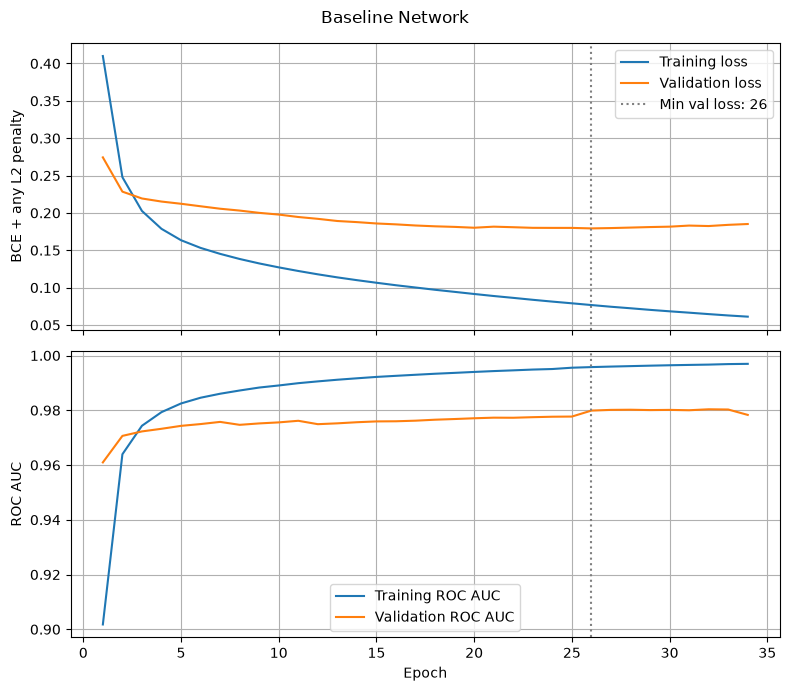

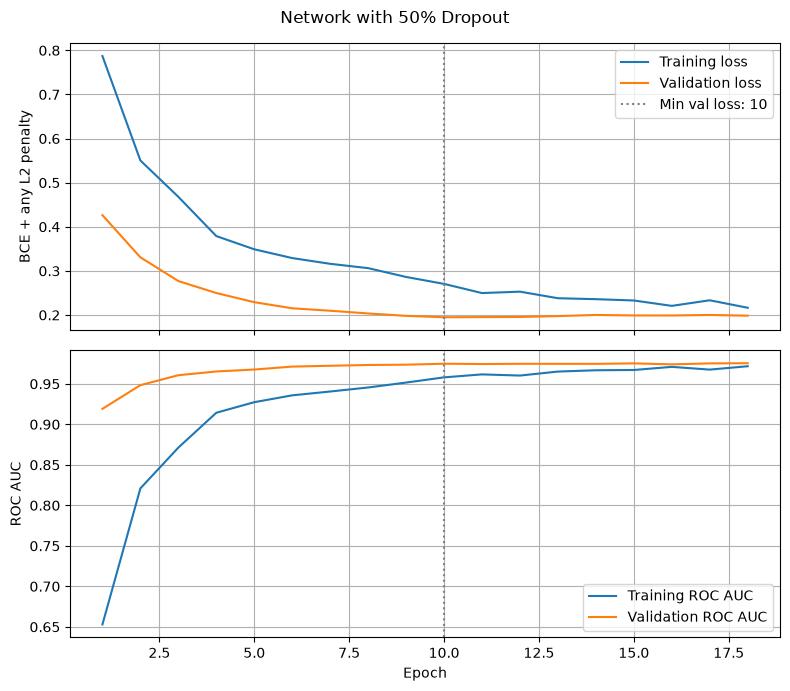

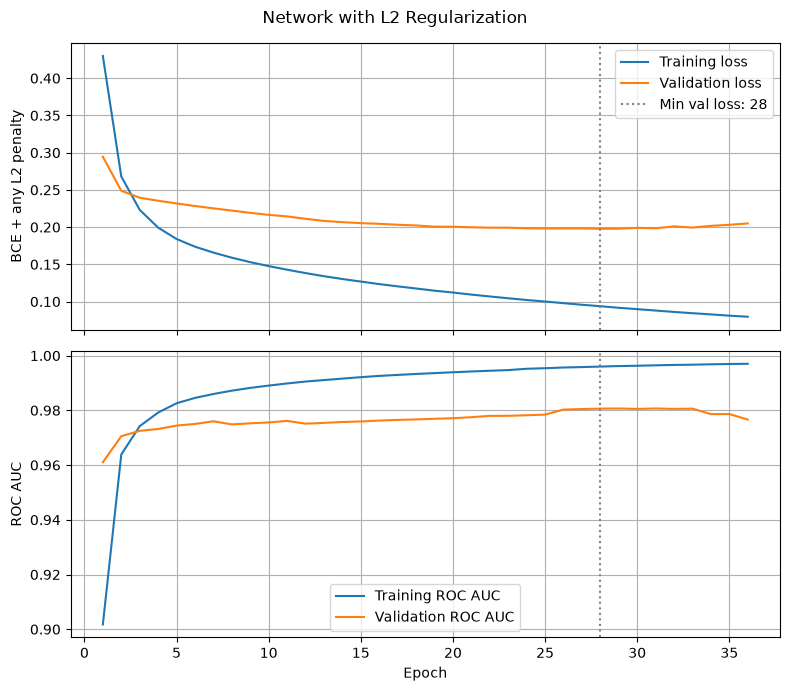

In [36]:
plot_history(
    experiment_results["baseline"]["history"],
    "Baseline Network"
)

plot_history(
    experiment_results["dropout_050"]["history"],
    "Network with 50% Dropout"
)

plot_history(
    experiment_results["l2_1e4"]["history"],
    "Network with L2 Regularization"
)

#### Problem 4 Graded Answers

In [37]:
# Your answer here — use a computed expression or variable
a4a = regularization_table.loc[0, "name"]

In [38]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting
print(f"a4a = {a4a}")

a4a = l2_1e4


In [39]:
# Your answer here — use a computed expression or variable
a4b = regularization_table.loc[0, "val_auc"]

In [40]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting
print(f"a4b = {a4b:.4f}")

a4b = 0.9817


In [41]:
# Your answer here — use a computed expression or variable
a4c = experiment_results["dropout_050"]["val_auc"]

In [42]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting
print(f"a4c = {a4c:.4f}")

a4c = 0.9747


In [43]:
# Your answer here — use a computed expression or variable
a4d = experiment_results["l2_1e4"]["val_bce"]

In [44]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting
print(f"a4d = {a4d:.4f}")

a4d = 0.1783


## Problem 5 — Select the Final Configuration and Evaluate on Test Data [10 points]

In Problems 3 and 4, you trained eight neural-network configurations and compared their performance using validation ROC AUC. You will now **select a final configuration based on those results**, train a fresh instance, and evaluate its performance on the held-out test set.

**This is the first time you should use the test set.** The test set provides an independent evaluation of your selected model and must not be used to make further modeling decisions.

### Instructions

1. **Select the best configuration.** Compare the validation ROC AUC values for all eight candidates:

   `small`, `baseline`, `large`, `batch_norm`, `dropout_025`, `dropout_050`, `l2_1e4`, `dropout_l2`.

   Select the configuration with the highest validation ROC AUC, breaking exact ties alphabetically. Retrieve its settings from `experiment_results` and store them in `selected_config`.

2. **Train the final neural network.** Train a fresh instance of the selected configuration using the same random seed and early-stopping procedure as before:

   ```python
   final_record = run_experiment("final_model", **selected_config)
   final_model = final_record["model"]
   ```

   Keep the configuration selected in Step 1, regardless of the fresh run's validation results. **Do not repeat model selection.**

3. **Evaluate the final model.** Generate predicted probabilities for the validation set:

   ```python
   nn_val_prob = final_model.predict(X_val_scaled, verbose=0).ravel()
   ```

   Then, for the first time, generate predicted probabilities for the test set:

   ```python
   nn_test_prob = final_model.predict(X_test_scaled, verbose=0).ravel()
   ```

   Calculate **validation and test ROC AUC** using the predicted probabilities. At a **0.50 classification threshold**, also calculate test accuracy, precision, recall, F1, and the confusion matrix. Display your results.

4. **Consider (ungraded):** Compare the final model's validation and test ROC AUC. Are they similar? What might explain any difference? Why would changing the model after examining test results compromise the validity of the evaluation?

5. **Compare with logistic regression.** After completing your graded answer cells, run the provided **Homework 05 comparison** cell. It trains logistic regression using the same training observations and compares both models on the same held-out test observations. Use this comparison in Reflection 7.B.

### A Note About the Comparison with Homework 05

In Homework 05, you refitted logistic regression on the full **90% development set** and selected a decision threshold using a business objective: achieve **TPR ≥ 0.95** while minimizing FPR.

For the comparison in this homework:

- Both models use the same **80% training set** and **10% test set**.
- **ROC AUC** evaluates discrimination across classification thresholds.
- Accuracy, precision, recall, and F1 are evaluated at a common **0.50 threshold**.

Therefore, the logistic regression results may differ from Homework 05. Use the results from this homework when making your comparison, particularly for threshold-dependent metrics.

### Graded Answers

- `a5a`: Validation ROC AUC of the freshly trained final neural network.
- `a5b`: Test ROC AUC of that neural network, calculated from `nn_test_prob`.

In [45]:
# Your code here; add cells as needed

all_names = [
    "small",
    "baseline",
    "large",
    "batch_norm",
    "dropout_025",
    "dropout_050",
    "l2_1e4",
    "dropout_l2"
]

all_results = comparison_table(all_names)

display(all_results)

,name,parameters,train_auc,val_auc,train_accuracy,val_accuracy,val_bce,best_epoch,epochs_ran
0,small,945,0.994595,0.984297,0.966576,0.947826,0.159773,97,105
1,l2_1e4,5825,0.996907,0.981742,0.978261,0.947826,0.178349,28,36
2,baseline,5825,0.996683,0.981326,0.977174,0.950000,0.179276,26,34
3,large,17793,0.996015,0.979326,0.977717,0.943478,0.177964,10,18
4,dropout_025,5825,0.985886,0.975881,0.946739,0.952174,0.196009,11,19
5,dropout_l2,5825,0.985893,0.975841,0.947283,0.947826,0.195678,11,19
6,dropout_050,5825,0.976835,0.974693,0.936141,0.943478,0.194861,10,18
7,batch_norm,6113,0.991584,0.973643,0.959239,0.952174,0.184100,14,22


In [46]:
selected_name = all_results.loc[0, "name"]

selected_config = experiment_results[
    selected_name
]["config"].copy()

print("Selected model:", selected_name)
print("Selected configuration:", selected_config)

final_record = run_experiment(
    "final_model",
    **selected_config
)

final_model = final_record["model"]

Selected model: small
Selected configuration: {'hidden_units': (16,), 'batch_norm': False, 'dropout_rate': 0.0, 'l2_strength': 0.0}
final_model         val ROC AUC=0.9843, val accuracy=0.9478, val BCE=0.1598, best epoch=97, epochs=105


E0000 00:00:1794181222.255371    2360 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


Validation ROC AUC: 0.9842967187469058
Test ROC AUC: 0.9732758281145379
Test accuracy: 0.928416485900217
Test precision: 0.9209039548022598
Test recall: 0.8956043956043956
Test F1: 0.9080779944289693
Confusion matrix:
[[265  14]
 [ 19 163]]


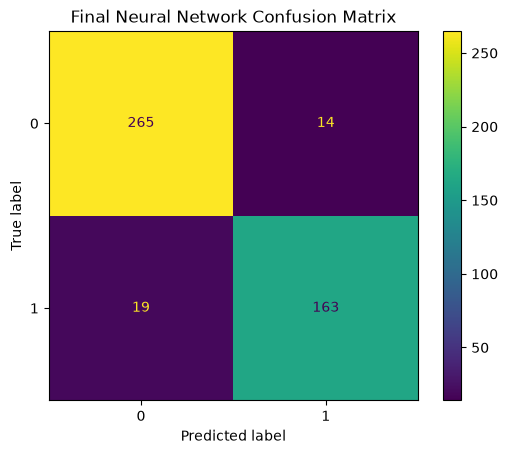

In [47]:
nn_val_prob = final_model.predict(
    X_val_scaled,
    verbose=0
).ravel()

nn_test_prob = final_model.predict(
    X_test_scaled,
    verbose=0
).ravel()

final_val_auc = roc_auc_score(y_val, nn_val_prob)
final_test_auc = roc_auc_score(y_test, nn_test_prob)

nn_test_pred = (nn_test_prob >= 0.50).astype(int)

test_accuracy = accuracy_score(y_test, nn_test_pred)
test_precision = precision_score(y_test, nn_test_pred)
test_recall = recall_score(y_test, nn_test_pred)
test_f1 = f1_score(y_test, nn_test_pred)
test_confusion = confusion_matrix(y_test, nn_test_pred)

print("Validation ROC AUC:", final_val_auc)
print("Test ROC AUC:", final_test_auc)
print("Test accuracy:", test_accuracy)
print("Test precision:", test_precision)
print("Test recall:", test_recall)
print("Test F1:", test_f1)
print("Confusion matrix:")
print(test_confusion)

ConfusionMatrixDisplay(
    confusion_matrix=test_confusion
).plot()

plt.title("Final Neural Network Confusion Matrix")
plt.show()

#### Problem 5 Graded Answers

In [48]:
# Your answer here — use a computed expression or variable
a5a = final_val_auc

In [49]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting
print(f"a5a = {a5a:.4f}")

a5a = 0.9843


In [50]:
# Your answer here — use a computed expression or variable
a5b = final_test_auc

In [51]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting
print(f"a5b = {a5b:.4f}")

a5b = 0.9733


### Provided Comparison — Logistic Regression versus the Final Neural Network

**Run the following cell only after completing Problem 5.**

This cell trains a logistic regression model using the same **3,680 training emails** as your neural network. Both models are then evaluated on the same **461 held-out test emails**.

The comparison table reports:

- **ROC AUC**, calculated from predicted probabilities.
- **Accuracy, precision, recall, and F1**, calculated using the same **0.50 classification threshold** for both models.

The logistic regression results may differ from Homework 05 because that homework used a different final training procedure and decision threshold.

Use this table to compare the two approaches in **Reflection 7.B**. The comparison is for interpretation only; **do not use these results to revise your selected neural network**.

In [52]:
# Provided Homework 05 reference comparison: run once AFTER final model selection.
# nn_test_prob must already have been computed in Problem 5.
logistic_baseline = LogisticRegression(max_iter=1000)
logistic_baseline.fit(X_train_scaled, y_train)
logistic_test_prob = logistic_baseline.predict_proba(X_test_scaled)[:, 1]
logistic_test_auc = roc_auc_score(y_test, logistic_test_prob)
nn_test_auc = roc_auc_score(y_test, nn_test_prob)

def summarize_test_predictions(model_name, probabilities):
    predicted = (probabilities >= 0.50).astype(int)
    return {
        "Model": model_name,
        "Test ROC AUC": roc_auc_score(y_test, probabilities),
        "Accuracy (0.50)": accuracy_score(y_test, predicted),
        "Precision (0.50)": precision_score(y_test, predicted, zero_division=0),
        "Recall (0.50)": recall_score(y_test, predicted, zero_division=0),
        "F1 (0.50)": f1_score(y_test, predicted, zero_division=0),
    }

model_comparison = pd.DataFrame([
    summarize_test_predictions("Logistic regression (HW05 approach)", logistic_test_prob),
    summarize_test_predictions("Final neural network", nn_test_prob),
]).set_index("Model")
display(model_comparison.round(4))
print("Neural network − logistic regression test ROC AUC:",
      f"{nn_test_auc - logistic_test_auc:+.4f}")


,Test ROC AUC,Accuracy (0.50),Precision (0.50),Recall (0.50),F1 (0.50)
Model,,,,,
Logistic regression (HW05 approach),0.9607,0.9132,0.8989,0.8791,0.8889
Final neural network,0.9733,0.9284,0.9209,0.8956,0.9081


Neural network − logistic regression test ROC AUC: +0.0126


## Problem 6 — Multiple-choice questions [10 points]

Select the **single best answer** (1, 2, 3, or 4) for each question. Each is worth 2 points.

### Part A — Early stopping

A model reaches its lowest validation loss at epoch 24. Training stops at epoch 32 after a patience period, with `restore_best_weights=True`. Which weights should it use for prediction?

1. Weights at epoch 32.
2. The average weights from epochs 24–32.
3. Weights from epoch 24.
4. Randomly initialized weights.

In [53]:
# Your answer here
a6a = 3   # Must be one of 1, 2, 3, 4

In [54]:
# Graded Answer
# DO NOT change this cell in any way
print(f"a6a = {a6a}")

a6a = 3


### Part B — Gradient flow and initialization

Which combination is generally appropriate for a deep network with ReLU hidden layers and can help avoid poorly scaled activations and gradients?

1. Sigmoid in all hidden layers with very large initial weights.
2. ReLU hidden layers with He initialization.
3. No nonlinear activations in any hidden layer.
4. Set every weight to zero.

In [55]:
# Your answer here
a6b = 2   # Must be one of 1, 2, 3, 4

In [56]:
# Graded Answer
# DO NOT change this cell in any way
print(f"a6b = {a6b}")

a6b = 2


### Part C — Batch Normalization

In the neural networks used in this homework, what does batch normalization primarily normalize during training?

1. The final classification labels.
2. The test set before fitting the scaler.
3. Intermediate activations within the network.
4. The dropout probability.


In [57]:
# Your answer here
a6c = 3   # Must be one of 1, 2, 3, 4

In [58]:
# Graded Answer
# DO NOT change this cell in any way
print(f"a6c = {a6c}")

a6c = 3


### Part D — L2 regularization

Why should we be cautious when comparing Keras `val_loss` between models with different L2 penalties?

1. The loss can include model-dependent regularization penalties.
2. The validation set automatically changes between models.
3. Keras does not calculate validation loss for classifiers.
4. L2 deletes all model weights before inference.

In [59]:
# Your answer here
a6d = 1   # Must be one of 1, 2, 3, 4

In [60]:
# Graded Answer
# DO NOT change this cell in any way
print(f"a6d = {a6d}")

a6d = 1


### Part E — Dropout

Which statement best describes dropout during model evaluation or inference?

1. It permanently deletes neurons before training starts.
2. It replaces the sigmoid output with softmax.
3. It randomly drops the same neurons in every prediction.
4. It is inactive during inference, with all neurons available.

In [61]:
# Your answer here
a6e = 4   # Must be one of 1, 2, 3, 4

In [62]:
# Graded Answer
# DO NOT change this cell in any way
print(f"a6e = {a6e}")

a6e = 4


## Problem 7 — Written Reflections [10 points]

Write two coherent responses of approximately **100–150 words each** in the indicated string variables. Support your conclusions with relevant results from your experiments. These reflections connect what you learned in Homework 10 with your ongoing project milestone.

### Reflection 7.A — Lessons for Your Project Milestone [5 points]

Identify **two techniques or lessons** from Homework 10 that could help you develop or evaluate the neural network in your project.

For each, explain when you might use it and what evidence you would examine to determine whether it was helpful. You may consider early stopping, model capacity, batch normalization, dropout, or L2 regularization.

Refer to **at least one numerical result from this homework** to support your reasoning.

You do not need to implement these improvements in your milestone. A reasonable baseline neural network is sufficient at that stage.

Write **approximately 100–150 words** in `a7a`.

### Reflection 7.B — Neural Networks versus Logistic Regression (Homework 05) [5 points]

Using the **comparison table from Problem 5**, compare your final neural network with logistic regression on the same Spambase test observations.

Report both test **ROC AUC** values and their difference. Compare at least one **threshold-dependent metric**, such as precision or recall at the common 0.50 threshold.

Explain a tradeoff involving false positives and false negatives in spam filtering. Finally, discuss whether the neural network's performance justifies its additional complexity and training cost, or whether logistic regression might be preferable.

Support your conclusions with the results. There is no single correct model choice, provided your reasoning is justified.

Write **approximately 100–150 words** in `a7b`.


In [63]:
# Your answer here
a7a = """Two things I would probably use in my project are early stopping and comparing a few different model sizes.
Early stopping was helpful because the lowest validation loss happened at epoch 26, even though the model trained for 34 epochs because of the patience setting.
I would use the learning curves to check whether validation loss starts getting worse while training loss keeps improving.
I also learned that a bigger model is not automatically better.
The small model had the highest validation ROC AUC at about 0.9843, while the large model reached about 0.9793.
For my project, I would compare training and validation ROC AUC instead of choosing a model based only on its size.
That would help me avoid adding complexity that does not actually improve performance on new data."""

In [64]:
# Graded Answer
# DO NOT change this cell in any way
print(f"a7a = {a7a}")

a7a = Two things I would probably use in my project are early stopping and comparing a few different model sizes.
Early stopping was helpful because the lowest validation loss happened at epoch 26, even though the model trained for 34 epochs because of the patience setting.
I would use the learning curves to check whether validation loss starts getting worse while training loss keeps improving.
I also learned that a bigger model is not automatically better.
The small model had the highest validation ROC AUC at about 0.9843, while the large model reached about 0.9793.
For my project, I would compare training and validation ROC AUC instead of choosing a model based only on its size.
That would help me avoid adding complexity that does not actually improve performance on new data.


In [65]:
# Your answer here
a7b = """The final neural network had a test ROC AUC of 0.9733, compared with 0.9607 for logistic regression, which was an improvement of about 0.0126.
At the 0.50 threshold, the neural network also had higher precision, 0.9209 compared with 0.8989, and higher recall, 0.8956 compared with 0.8791.
In spam filtering, higher recall means catching more spam, but increasing recall can sometimes cause more legitimate emails to be marked as spam.
That is a problem because a false positive could cause someone to miss an important email, while a false negative allows spam into the inbox.
The neural network performed better on every metric here, so I think the extra complexity may be worth it.
However, the improvement was not huge, so logistic regression could still be a good choice if faster training and easier interpretation are more important."""

In [66]:
# Graded Answer
# DO NOT change this cell in any way
print(f"a7b = {a7b}")

a7b = The final neural network had a test ROC AUC of 0.9733, compared with 0.9607 for logistic regression, which was an improvement of about 0.0126.
At the 0.50 threshold, the neural network also had higher precision, 0.9209 compared with 0.8989, and higher recall, 0.8956 compared with 0.8791.
In spam filtering, higher recall means catching more spam, but increasing recall can sometimes cause more legitimate emails to be marked as spam.
That is a problem because a false positive could cause someone to miss an important email, while a false negative allows spam into the inbox.
The neural network performed better on every metric here, so I think the extra complexity may be worth it.
However, the improvement was not huge, so logistic regression could still be a good choice if faster training and easier interpretation are more important.


## Submission checklist

- [ ] Run all required cells from a fresh kernel; keep relevant tables and learning curves visible.
- [ ] Verify that every numeric graded answer is **computed** from a model/history/table, not manually transcribed.
- [ ] Complete `a1a`–`a1c`, `a2a`–`a2c`, `a3a`–`a3d`, `a4a`–`a4d`, `a5a`–`a5b`, `a6a`–`a6e`, `a7a`, and `a7b`.
- [ ] Run each **Graded Answer** cell without editing it.
- [ ] Check that the held-out test partition is used **only** in Problem 5.
- [ ] Submit the `.ipynb` notebook in Gradescope.